# Jupyter notebook sample

In [77]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

### Импортируем файлы

In [87]:
fields_df = pd.read_csv('fields.csv', sep=';', skiprows=[0,2],
                      encoding='cp1251', decimal=',')
works_df = pd.read_csv('works.csv', sep=';', skiprows=[0,1],
                     encoding='cp1251', decimal=',')
value_df = pd.read_csv('value.csv', sep=';', skiprows=[0,1],
                     encoding='cp1251', decimal=',')

fields_df.columns = fields_df.columns.str.lower()
works_df.columns = works_df.columns.str.lower()
value_df.columns = value_df.columns.str.lower()


In [79]:
value_df['inv_item_date'] = pd.to_datetime(value_df['inv_item_date'],
                                           format='%d.%m.%Y')
works_df['start_date'] = pd.to_datetime(works_df['start_date'],
                                        format='%d.%m.%Y')
works_df['end_date'] = pd.to_datetime(works_df['end_date'], format='%d.%m.%Y')

works_df['area'] = works_df['area'].replace({',': '.'}, regex=True).astype(
    float)
works_df['prod_weight'] = works_df['prod_weight'].replace({',': '.'},
                                                          regex=True).astype(
    float)
works_df['prod_dry_perc'] = works_df['prod_dry_perc'].replace({',': '.'},
                                                              regex=True).astype(
    float)
works_df['prod_humid'] = works_df['prod_humid'].replace({',': '.'},
                                                        regex=True).astype(
    float)
works_df['prod_impur'] = works_df['prod_impur'].replace({',': '.'},
                                                        regex=True).astype(
    float)
works_df['yield_fact'] = works_df['yield_fact'].replace({',': '.'},
                                                        regex=True).astype(
    float)

for col in ['yield_plan', 'p2o5', 'k2o', 'humus', 'ph', 'area',
            'fertility_score']:
    if col in fields_df.columns:
        fields_df[col] = fields_df[col].replace({',': '.'}, regex=True).astype(
            float)

works_df

,season,field,work_type,work_subtype,start_date,end_date,area,main_tech,add_tech,mech,proc_depth,prod_purpose,prod_weight,prod_dry_perc,prod_humid,prod_impur,yield_fact,work_id
0,2023,16.13.12.044.00,Обработка почвы,Боронование,2022-04-29,2022-04-30,49.78,"Трактор колесный Fendt 936 Vario, гос.ном. 050...",Арендованная техника,Ахметсафин Айрат Рафикович,"10,00",NaN,0.00,NaN,NaN,NaN,0.00,A06AD38A-5448-40EC-B095-4B8918B4AC10
1,2023,16.13.12.017.00,Обработка почвы,Боронование,2022-05-01,2022-05-02,154.76,"Трактор колесный Птз К-744Р4, гос.ном. 2251АА1...","Борона зубовая Veles АГС-22-2У.М, зав.ном. 789",Ямалетдинов Фарид Расыхович,"10,00",NaN,0.00,NaN,NaN,NaN,0.00,62B13DCE-FFB5-4E7A-8F1B-88930BD338EF
2,2023,16.13.12.012.00,Обработка почвы,Боронование,2022-05-02,2022-05-03,40.62,"Трактор колесный Fendt 936 Vario, гос.ном. 050...",Арендованная техника,Мухаметзянов Ринат Айратович,"10,00",NaN,0.00,NaN,NaN,NaN,0.00,D5884A6D-4710-4C0A-8E5A-878291B89846
3,2023,16.13.12.012.00,Обработка почвы,Боронование,2022-05-02,2022-05-03,86.00,"Трактор колесный Птз К-744Р4, гос.ном. 2251АА1...","Борона зубовая Veles АГС-22-2У.М, зав.ном. 789",Шакиров Ринат Галиевич,"10,00",NaN,0.00,NaN,NaN,NaN,0.00,7A504837-1127-4315-ACF1-171AC80111BF
4,2023,16.13.12.017.00,Обработка почвы,Боронование,2022-05-02,2022-05-03,76.00,"Трактор колесный Птз К-744Р4, гос.ном. 2251АА1...","Борона зубовая Veles АГС-22-2У.М, зав.ном. 789",Шакиров Ринат Галиевич,"10,00",NaN,0.00,NaN,NaN,NaN,0.00,7FE86DA8-614B-4EBE-85CB-6AF80C08689F
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
174678,2024,54.17.12.029.00,Уборка,Подбор (корм),2024-10-27,2024-10-27,27.00,"Комбайн кормоуборочный Ростсельмаш F2650, гос....",NaN,Ульвачев Алексей Николаевич,NaN,NaN,0.00,NaN,NaN,NaN,0.00,2B7459EA-D3E8-43A6-A195-EBC5670C5266
174679,2024,54.28.13.038.00,Уборка,Вывоз,2024-10-27,2024-10-27,7.00,"Трактор колесный Lovol 2604, зав.ном. M700060R...",Арендованная техника,Лагунов Юрий Николаевич,NaN,солома,9.45,85.0,NaN,NaN,1.15,63C37AF5-60EC-492A-A396-CA750B656725
174680,2024,54.28.07.028.00,Обработка почвы,Культивация,2024-10-28,2024-10-28,3.14,"Трактор колесный John Deere 8370R, гос.ном. 49...","Культиватор стерневой Vaderstad TopDown 500, з...",Гопаненко Владимир Владимирович,"15,00",NaN,0.00,NaN,NaN,NaN,0.00,69939CB6-C816-42F4-97C9-751D943782CF
174681,2024,54.28.07.028.00,Обработка почвы,Культивация,2024-10-28,2024-10-28,6.00,"Трактор колесный John Deere 9470R, гос.ном. 48...","Культиватор стерневой Vaderstad TopDown 700, и...",Гамануха Дмитрий Владимирович,"15,00",NaN,0.00,NaN,NaN,NaN,0.00,14CD020E-CC81-41FC-9593-571DB0E0C16E


### Гипотеза 1: Влияние времени внесения удобрений на урожайность

In [80]:
harvest_2023 = works_df[
    (works_df['season'] == 2023) & (works_df['work_type'] == 'Уборка')].copy()
harvest_summary = harvest_2023.groupby('field', as_index=False).agg({
    'end_date': 'max',
    'area': 'max',
    'prod_weight': 'sum'
})

harvest_summary.rename(columns={'end_date': 'harvest_date'}, inplace=True)
harvest_summary['yield_field'] = (
        harvest_summary['prod_weight'] / harvest_summary['area']
)
harvest_summary

,field,harvest_date,area,prod_weight,yield_field
0,02.09.02.002.01,NaT,33.25,188.94,5.682406
1,02.09.02.015.00,NaT,7.71,44.38,5.756161
2,02.09.02.019.00,NaT,50.78,109.28,2.152028
3,02.09.03.032.00,NaT,27.42,28326.02,1033.042305
4,02.09.06.004.01,NaT,15.00,60802.00,4053.466667
...,...,...,...,...,...
4998,72.22.10.043.00,2023-10-08,55.09,523.25,9.498094
4999,72.22.10.044.00,2023-07-01,20.70,59.85,2.891304
5000,72.22.10.046.00,2023-09-08,5.56,6.93,1.246403
5001,72.22.10.047.00,2023-10-05,7.13,135.80,19.046283


In [81]:
fert_usage = value_df[value_df['inv_item_type'] == 'Удобрения'].copy()
fert_usage = fert_usage.merge(
    works_df[['work_id', 'field', 'season', 'end_date']],
    on='work_id',
    how='left'
)

fert_usage = fert_usage[fert_usage['season'] == 2023]
fert_usage = fert_usage.merge(
    harvest_summary[['field', 'harvest_date', 'yield_field']],
    left_on='field_x',
    right_on='field',
    how='inner'
)
fert_usage

,field_x,inv_item_type,inv_item_name,inv_item_weight,inv_item_unit,inv_item_dose,inv_item_date,work_id,field_y,season,end_date,field,harvest_date,yield_field
0,40.14.07.019.01,Удобрения,Удобрение 49,"874640,00",т,"260,00",2023-11-19,79B0CCBB-C75E-487D-A97F-C607FF2A754F,40.14.07.019.01,2023.0,2023-11-19,40.14.07.019.01,2023-07-18,3.361645
1,36.14.11.018.01,Удобрения,Удобрение 49,"5265,00",т,"65,00",2023-11-08,9976CD62-C1B7-45F2-AFEB-9CC329F1FE4A,36.14.11.018.01,2023.0,2023-11-08,36.14.11.018.01,2023-08-10,4.197205
2,36.14.11.018.01,Удобрения,Удобрение 49,"1966,25",т,"65,00",2023-11-08,70BC69A4-8D36-4AA6-A015-E49734FEA23E,36.14.11.018.01,2023.0,2023-11-08,36.14.11.018.01,2023-08-10,4.197205
3,36.14.11.018.01,Удобрения,Удобрение 49,"1966,25",т,"65,00",2023-11-08,70B14790-C7B0-4A0C-915F-3ACE7D2CCBF9,36.14.11.018.01,2023.0,2023-11-08,36.14.11.018.01,2023-08-10,4.197205
4,40.14.07.019.01,Удобрения,Удобрение 49,"1132560,00",т,"260,00",2023-11-08,629AF250-667E-4899-971D-38CC3FFDDDA1,40.14.07.019.01,2023.0,2023-11-18,40.14.07.019.01,2023-07-18,3.361645
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12906,16.13.12.059.00,Удобрения,Удобрение 38,"4744,34",кг,"0,39",2022-06-23,A6744CF5-4AE9-42B6-848B-ED9BB080B8B0,16.13.12.059.00,2023.0,2022-06-23,16.13.12.059.00,2023-08-08,2.118778
12907,16.13.12.066.00,Удобрения,Удобрение 38,"3159,00",кг,"0,39",2022-06-23,9F552625-E91C-4B3F-ABB4-5E565D4A7687,16.13.12.066.00,2023.0,2022-06-23,16.13.12.066.00,2023-09-15,2.178087
12908,16.13.12.068.00,Удобрения,Удобрение 38,"2951,91",кг,"0,39",2022-06-23,EB59990D-0C80-4894-9EE6-03FC89F4A8C5,16.13.12.068.00,2023.0,2022-06-23,16.13.12.068.00,2023-08-09,0.000000
12909,16.13.12.069.00,Удобрения,Удобрение 38,"711,08",кг,"0,39",2022-06-23,AB7177FA-F620-48E4-856F-D1424F119416,16.13.12.069.00,2023.0,2022-06-23,16.13.12.069.00,2023-08-09,0.000000


In [82]:
fert_usage = fert_usage[
    fert_usage['inv_item_date'] <= fert_usage['harvest_date']]

fert_last = fert_usage.sort_values('inv_item_date').groupby('field').tail(1)

fert_last['delta_days'] = (
        fert_last['harvest_date'] - fert_last['inv_item_date']
).dt.days

fert_last['delta_days'] = (
        fert_last['harvest_date'] - fert_last['inv_item_date']
).dt.days

corr_coef = fert_last['delta_days'].corr(fert_last['yield_field'])
print(f"Корр Пирсона: {corr_coef:.3f}")

Корр Пирсона: -0.008


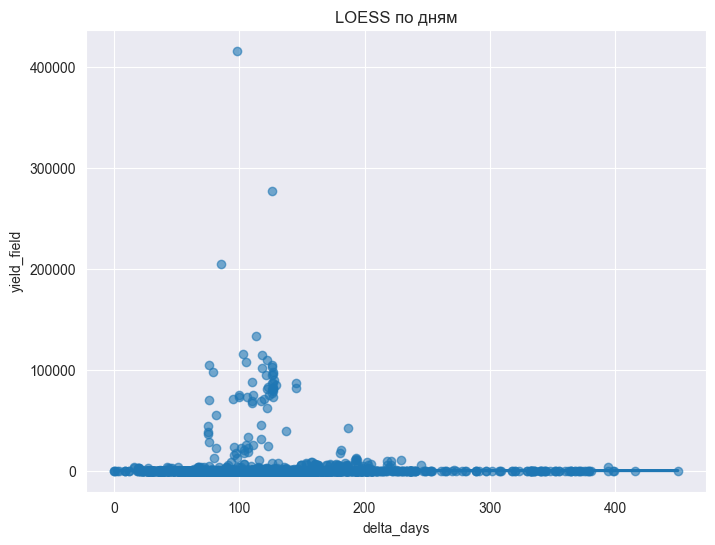

In [83]:
plt.figure(figsize=(8, 6))
sns.regplot(
    x='delta_days',
    y='yield_field',
    data=fert_last,
    lowess=True,
    scatter_kws={'alpha': 0.6}
)
plt.title('LOESS по дням')
plt.grid(True)
plt.show()

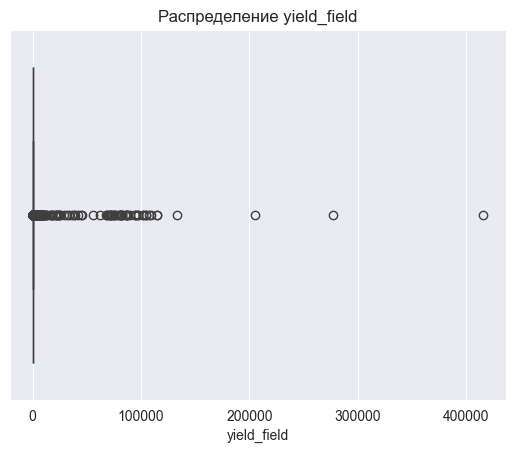

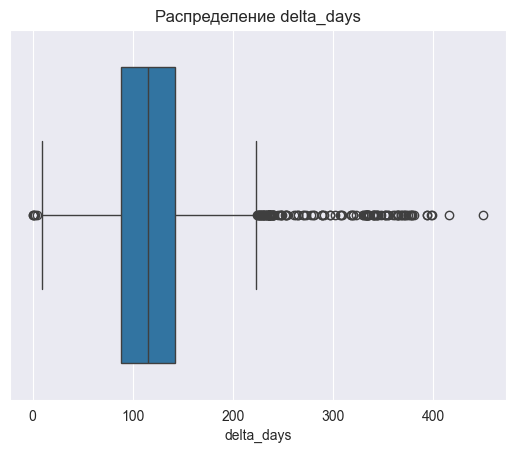

In [84]:
sns.boxplot(x=fert_last['yield_field'])
plt.title('Распределение yield_field')
plt.show()

sns.boxplot(x=fert_last['delta_days'])
plt.title('Распределение delta_days')
plt.show()


In [85]:
corr_spearman, pvalue = spearmanr(fert_last['delta_days'],
                                  fert_last['yield_field'])
print(f"spearman log: {corr_spearman:.3f}, p-value={pvalue:.3f}")


spearman log: 0.208, p-value=0.000


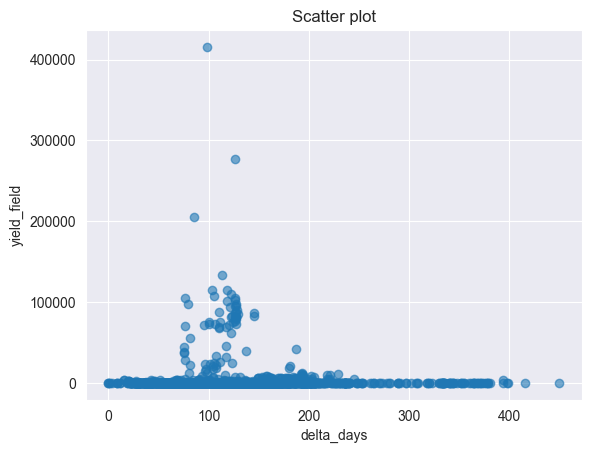

In [86]:
plt.scatter(fert_last['delta_days'], fert_last['yield_field'], alpha=0.6)
plt.xlabel('delta_days')
plt.ylabel('yield_field')
plt.title('Scatter plot')
plt.grid(True)
plt.show()